# Chunk 50 — Re-run the 12×12 → 15×15 replay chain from the Chunk 45 model

**Why:** the table's GATv2 for 12×12 and 15×15 comes from this chain:

`backbone_no55` → Chunk 42 `ft12_replay` → Chunk 44 `ft15_from4_replay`

That chain never saw the 1,997 extra 35×35 antennas. Chunk 45's model (`replay35_new100_s0`) did, and it scored slightly better on 25/35/45. This chunk repeats the same chain from the Chunk 45 model, producing **one GATv2 for all five grids that includes the extra data**, then measures it on every test set.

**Chain (recipes copied from Chunks 42 and 44, unchanged):**

| stage | starts from | trains on | replay per epoch | selection |
|---|---|---|---|---|
| 1 `ft12_replay_from45` | `ch45_replay35_new100_s0` | 12×12 pool (5,600) | 5,600 each from 25 / 35 / 45 | 12×12 val MSE |
| 2 `ft15_from4_replay_from45` | stage 1 | 15×15 pool (5,092) | 5,092 each from 12 / 25 / 35 / 45 | 15×15 val MSE |

- **Optimiser:** Adam, lr 1e-4, weight decay 1e-4, batch 64.
- **Schedule:** ReduceLROnPlateau (factor 0.5, patience 5); early stopping with patience 10; at most 60 epochs.
- **Seeds:** torch 1000+s; replay sampling 4200+s (stage 1) and 4400+s (stage 2), as in Chunks 42/44.
- **The only data change:** the 35×35 replay pool is now the original 3,990 **plus Chunk 45's 1,997** (5,987). Because 5,987 ≥ 5,600, 35×35 replay no longer needs sampling with replacement.

**Test (one touch), on all five test sets:**
- the new five-grid model
- the old five-grid model (`ch44_ft15_from4_replay_p100_s0`), reproduced against Chunk 44
- Chunk 45's model on 25/35/45, reproduced against Chunk 45

The Gupta CNN numbers come from Chunk 49's saved per-antenna results, so the comparison against the CNN is paired, on the same test antennas.

**Pre-registered statements:**

| | question |
|---|---|
| S1 | Does the new chain change **12×12** test MSE/MAE compared with the old five-grid model? |
| S2 | Does it change **15×15** test MSE/MAE compared with the old five-grid model? |
| S3 | Are 25/35/45 preserved compared with the Chunk 45 model it started from? |
| S4 | Is the new model better than the Gupta CNN on each grid? |

**Writes:**
- `ch50_*` artifacts: runs, curves, per-sample, metrics, paired comparisons, report
- `ch50_table_gatv2_vs_gupta_cnn.{png,pdf}`
- `checkpoints/ch50_*.pt`

## 1. Installs

In [1]:
!pip -q install torch_geometric pyarrow tabulate

## 2. Repository and Drive

In [2]:
import os, sys, subprocess
REPO_ROOT = '/content/antenna_gnn'
if os.path.isdir(f'{REPO_ROOT}/.git'):
    subprocess.run(['git', '-C', REPO_ROOT, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/asparagusD/antenna_gnn.git', REPO_ROOT], check=True)
sys.path.insert(0, f'{REPO_ROOT}/src')
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT = '/content/drive/MyDrive/antenna_gnn'
ART, CKPT, SPLITS, LOCAL = f'{DATA_ROOT}/artifacts', f'{DATA_ROOT}/checkpoints', f'{DATA_ROOT}/splits', '/content/local_graphs'
os.makedirs(LOCAL, exist_ok=True)
print(REPO_ROOT, DATA_ROOT)

Mounted at /content/drive
/content/antenna_gnn /content/drive/MyDrive/antenna_gnn


## 3. Setup
- **Determinism:** deterministic cuDNN, TF32 off.
- **Provenance:** hashes every input file and captures the mtimes of earlier files, so the guards can prove nothing earlier was changed.
- **Statistics:** loads the canonical 25×25 normalisation statistics read-only.
- **Starting model:** asserts that Chunk 45's model `replay35_new100_s0` is the checkpoint Chunk 45 recorded, by SHA-256.

In [3]:
# ── Setup: scope, provenance, determinism ──
import json, glob, hashlib, zipfile, shutil, time, textwrap
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GeoLoader
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from model import AntennaGNN
from feed_component import AppendFeedComponentFeature

TAU, F = -10.0, np.linspace(1, 4, 201)
GRIDS = (12, 15, 25, 35, 45)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); assert DEVICE.type == 'cuda', 'GPU required'
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
def sha(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()
READ_SHA = {}
def READ(p):
    assert os.path.exists(p), f'missing {p}'
    READ_SHA.setdefault(p, sha(p)); return p
def OUT(n):
    assert n.startswith('ch50_'), n; return f'{ART}/{n}'
def COUT(n):
    assert n.startswith('ch50_') and n.endswith('.pt'), n; return f'{CKPT}/{n}'
PRIOR = {p: os.path.getmtime(p) for pat in (f'{ART}/*', f'{SPLITS}/*', f'{CKPT}/*.pt') for p in glob.glob(pat)
         if os.path.isfile(p) and not Path(p).name.startswith('ch50_')}
MEAN = torch.tensor(np.load(READ(f'{ART}/s11_mean.npy')), dtype=torch.float32)   # canonical 25x25 statistics, read only
STD = torch.tensor(np.load(READ(f'{ART}/s11_std.npy')), dtype=torch.float32)
MEAN_D, STD_D = MEAN.to(DEVICE), STD.to(DEVICE)
START_ID, START_PATH = 'replay35_new100_s0', f'{CKPT}/ch45_replay35_new100_s0.pt'
OLD_ID, OLD_PATH = 'ft15_from4_replay_p100_s0', f'{CKPT}/ch44_ft15_from4_replay_p100_s0.pt'
R45 = pd.read_csv(READ(f'{ART}/ch45_runs.csv')).set_index('run_id')
assert sha(READ(START_PATH)) == R45.loc[START_ID, 'checkpoint_sha256'], 'STOP: ch45_replay35_new100_s0.pt is not the checkpoint Chunk 45 recorded'
EXTRA35_ZIP = f'{DATA_ROOT}/data/processed/processed_35x35_extra.zip'
REP45 = json.load(open(READ(f'{ART}/ch45_preprocess_report.json')))
MAN45 = pd.read_csv(READ(f'{ART}/ch45_manifest_35x35_extra.csv'))
TEST_TOUCHES = 0
print(f'GPU: {torch.cuda.get_device_name(0)} | start: {START_ID} (SHA verified) | captured mtimes of {len(PRIOR)} earlier files')

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | start: replay35_new100_s0 (SHA verified) | captured mtimes of 271 earlier files


## 4. Splits
The same split files as Chunks 42–45, with sizes asserted. The 35×35 **training/replay** pool adds Chunk 45's 1,997 de-duplicated antennas; val and test are unchanged.

In [4]:
# ── Splits ──
def pairs(v):
    if isinstance(v, dict):
        return {(int(g), int(i)) for g, x in v.items() for i in x}
    return {(int(e[0]), int(e[1])) for e in v}
S = {}
for N in (12, 15):
    S[N] = {r: sorted(i for g, i in pairs(json.load(open(READ(f'{SPLITS}/finetune{N}_{r}_indices.json'))))) for r in ('pool', 'val', 'test')}
IDX = json.load(open(READ(f'{SPLITS}/indices.json')))
S[25] = {r: sorted(i for g, i in pairs(IDX[k]) if g == 25) for r, k in (('pool', 'train'), ('val', 'val'), ('test', 'test'))}
FTI = {r: pairs(json.load(open(READ(f'{SPLITS}/finetune_{r}_indices.json')))) for r in ('pool', 'val', 'test')}
for N in (35, 45):
    S[N] = {r: sorted(i for g, i in FTI[r] if g == N) for r in ('pool', 'val', 'test')}
EXPECT = {12: (5600, 700, 700), 15: (5092, 638, 637), 25: (79866, 9984, 9983), 35: (3990, 499, 499), 45: (5587, 698, 699)}
for N in GRIDS:
    a, b, c = (set(S[N][r]) for r in ('pool', 'val', 'test'))
    assert not (a & b or a & c or b & c) and (len(a), len(b), len(c)) == EXPECT[N], f'STOP: {N}x{N} splits'
EXTRA35 = sorted(int(i) for i in REP45['new_pool_sample_idx'])
st = MAN45.set_index('sample_idx').status
assert len(EXTRA35) == 1997 and all(st[i] == 'new' for i in EXTRA35), 'STOP: Chunk 45 extra list is not the 1,997 de-duplicated antennas'
# replay sources: key = (source, index); source '35x' = Chunk 45's extra 35x35 antennas
POOLKEYS = {N: [(N, i) for i in S[N]['pool']] for N in GRIDS}
POOLKEYS[35] = POOLKEYS[35] + [('35x', i) for i in EXTRA35]
for N in GRIDS:
    print(f'{N}x{N}: train/replay pool {len(POOLKEYS[N]):,} | val {len(S[N]["val"]):,} | test {len(S[N]["test"]):,}')

12x12: train/replay pool 5,600 | val 700 | test 700
15x15: train/replay pool 5,092 | val 638 | test 637
25x25: train/replay pool 79,866 | val 9,984 | test 9,983
35x35: train/replay pool 5,987 | val 499 | test 499
45x45: train/replay pool 5,587 | val 698 | test 699


## 5. Stage graphs and cache
**What it does:**
- Unzips each grid's processed graphs, plus `processed_35x35_extra.zip`, to local SSD.
- Caches every graph in RAM the first time it's used, with the 8-connected feed-component column appended once, as in Chunks 42/44.

In [5]:
# ── Stage graphs; cache 6-feature graphs in RAM ──
FOLDER = {N: f'{LOCAL}/{N}x{N}' for N in GRIDS}; FOLDER['35x'] = f'{LOCAL}/35x35_extra'
ZIPS = {N: f'{DATA_ROOT}/data/processed/processed_{N}x{N}.zip' for N in GRIDS}; ZIPS['35x'] = EXTRA35_ZIP
for src, d in FOLDER.items():
    if os.path.exists(f'{d}/_STAGED.txt'):
        continue
    os.makedirs(d, exist_ok=True)
    with zipfile.ZipFile(READ(ZIPS[src])) as Z:
        mem = [m for m in Z.namelist() if m.endswith('.pt')]
        for m in tqdm(mem, desc=f'stage {src}'):
            with Z.open(m) as a, open(f'{d}/{os.path.basename(m)}', 'wb') as b:
                shutil.copyfileobj(a, b)
    open(f'{d}/_STAGED.txt', 'w').write(str(len(mem)))
TRANSFORM = AppendFeedComponentFeature()
CACHE = {}
def graph(src, i):
    # 6-feature graph from a source (12, 15, 25, 35, 45 or '35x'), cached; y normalised, y_raw in dB
    k = (src, int(i))
    if k not in CACHE:
        n_ = 35 if src == '35x' else src
        d = torch.load(f'{FOLDER[src]}/sample_{int(i)}.pt', weights_only=False)
        assert d.x.shape == (n_ * n_ + 1, 5) and float(d.x[-1, 3]) == -1.0 and d.y.numel() == 201 and float(d.y.max()) <= 0.01
        g = TRANSFORM(Data(x=d.x.clone(), edge_index=d.edge_index, edge_attr=d.edge_attr))
        CACHE[k] = (g.x, g.edge_index, g.edge_attr, d.y.reshape(1, 201).float())
    x, ei, ea, y = CACHE[k]
    return Data(x=x, edge_index=ei, edge_attr=ea, y=(y - MEAN) / (STD + 1e-8), y_raw=y)
def truth(N, ids):
    return np.stack([graph(N, i).y_raw.reshape(-1).numpy() for i in ids]).astype(np.float64)
print('staged:', {k: open(f'{v}/_STAGED.txt').read() for k, v in FOLDER.items()})

stage 12:   0%|          | 0/7000 [00:00<?, ?it/s]

stage 15:   0%|          | 0/6367 [00:00<?, ?it/s]

stage 25:   0%|          | 0/99833 [00:00<?, ?it/s]

stage 35:   0%|          | 0/4988 [00:00<?, ?it/s]

stage 45:   0%|          | 0/6984 [00:00<?, ?it/s]

stage 35x:   0%|          | 0/1997 [00:00<?, ?it/s]

staged: {12: '7000', 15: '6367', 25: '99833', 35: '4988', 45: '6984', '35x': '1997'}


## 6. Models
**What it does:**
- **GATv2:** six inputs, 587,129 parameters, the same architecture as every fine-tuned model since Chunk 30.
- **Loads:** the Chunk 45 starting model and the old five-grid model (for comparison).
- **Predict helper:** returns predictions in raw dB.

In [6]:
# ── Models ──
def gnn(nf=6):
    return AntennaGNN(node_feat_dim=nf, edge_feat_dim=2, hidden_dim=128, heads=8, edge_dim=16, num_blocks=4, output_dim=201)
def n_par(m):
    return sum(p.numel() for p in m.parameters())
def state_of(path):
    c = torch.load(READ(path), map_location='cpu', weights_only=False)
    s = c['model_state'] if isinstance(c, dict) and 'model_state' in c else c
    return {k[7:] if k.startswith('module.') else k: v for k, v in s.items()}
def load(path):
    m = gnn(); m.load_state_dict(state_of(path), strict=True); assert n_par(m) == 587_129; return m
START, OLD = load(START_PATH), load(OLD_PATH)
@torch.no_grad()
def predict(m, N, ids, bs=128):
    m = m.to(DEVICE).eval(); out = []
    for s in range(0, len(ids), bs):
        gs = [graph(N, i) for i in ids[s:s + bs]]
        out.append((m(next(iter(GeoLoader(gs, batch_size=len(gs)))).to(DEVICE)) * STD_D + MEAN_D).double().cpu())
    return torch.cat(out).numpy()
print(f'starting model {START_ID} and old five-grid model {OLD_ID}: 587,129 parameters each')

starting model replay35_new100_s0 and old five-grid model ft15_from4_replay_p100_s0: 587,129 parameters each


## 7. VAL harness (before training)
**What it checks:**
- **Chunk 45 model:** its full 35×35 and 45×45 val MSE must reproduce `ch45_runs.csv`.
- **Old five-grid model:** its 15×15 val MSE must reproduce `ch44_runs.csv`, and its 12×12 val MSE is printed.
- **Context:** prints the Chunk 45 model's zero-shot 12×12 and 15×15 val MSE, the starting point for this chain.

In [7]:
# ── VAL harness (before any training) ──
def vmse(m, N): return float(((predict(m, N, S[N]['val']) - truth(N, S[N]['val'])) ** 2).mean())
for N in (35, 45):
    v, ref = vmse(START, N), float(R45.loc[START_ID, f'val{N}_mse'])
    print(f'{START_ID} {N}x{N} VAL MSE {v:.4f} | Chunk 45 {ref:.4f}')
    assert abs(v - ref) < 0.01, f'STOP: the Chunk 45 model does not reproduce its {N}x{N} val MSE'
R44 = pd.read_csv(READ(f'{ART}/ch44_runs.csv')).set_index('run_id')
v, ref = vmse(OLD, 15), float(R44.loc[OLD_ID, 'val15_mse_db2'])
print(f'{OLD_ID} 15x15 VAL MSE {v:.4f} | Chunk 44 {ref:.4f}')
assert abs(v - ref) < 0.01, 'STOP: the old five-grid model does not reproduce Chunk 44'
print(f'{OLD_ID} 12x12 VAL MSE {vmse(OLD, 12):.4f}')
for N in (12, 15):
    print(f'{START_ID} zero-shot {N}x{N} VAL MSE {vmse(START, N):.4f}  (starting point)')
HARNESS = True

replay35_new100_s0 35x35 VAL MSE 1.2861 | Chunk 45 1.2861
replay35_new100_s0 45x45 VAL MSE 1.0791 | Chunk 45 1.0791
ft15_from4_replay_p100_s0 15x15 VAL MSE 1.9001 | Chunk 44 1.9001
ft15_from4_replay_p100_s0 12x12 VAL MSE 2.0718
replay35_new100_s0 zero-shot 12x12 VAL MSE 3.8696  (starting point)
replay35_new100_s0 zero-shot 15x15 VAL MSE 3.3376  (starting point)


## 8. Train the chain (resumable)
**Queue:** stage 1 then stage 2 for each seed in `SEEDS`. The default is seed 0; set `SEEDS = (0, 1)` for a second seed.
- Stage 2 of a seed starts from that seed's stage-1 checkpoint.
- A finished run is skipped. An interrupted run restarts from scratch, with its old curve rows removed first.

**Every epoch:**
- **Data:** the target pool, plus fresh random replay draws from the other grids. 35×35 draws come from all 5,987 antennas.
- **Forgetting monitor:** val MSE on fixed 1,000-antenna subsets of the other grids, logged at epoch 1 and every 5 epochs.

**Checkpoints:** the best model by the target grid's val MSE is mirrored to Drive with a forced flush and verified by SHA-256.

**Writes:** `ch50_curves.csv`, `ch50_runs.csv`, `checkpoints/ch50_<run>.pt`.

In [8]:
# ── Training: stage 1 (12x12 + replay 25/35/45) -> stage 2 (15x15 + replay 12/25/35/45) ──
RECIPE = dict(lr=1e-4, wd=1e-4, batch=64, patience=10, max_ep=60)          # Chunk 42/44 replay arms, unchanged
STAGES = {'ft12_replay_from45':       dict(target=12, replay=(25, 35, 45),     per_grid=5600, rng=4200, init='start'),
          'ft15_from4_replay_from45': dict(target=15, replay=(12, 25, 35, 45), per_grid=5092, rng=4400, init='ft12_replay_from45')}
SEEDS = (0,)
QUEUE = [(arm, s) for s in SEEDS for arm in STAGES]
CURVES, RUNS = OUT('ch50_curves.csv'), OUT('ch50_runs.csv')
SESSION_HOURS = 10; T0S = time.perf_counter(); TIMES = []
MON = {N: sorted(np.random.default_rng(42).choice(S[N]['val'], min(1000, len(S[N]['val'])), replace=False).tolist()) for N in GRIDS}
def rid(arm, s): return f'{arm}_s{s}'
def ckpt(arm, s): return COUT(f'ch50_{rid(arm, s)}.pt')
def done(): return set(pd.read_csv(RUNS).run_id) if os.path.exists(RUNS) else set()
def append(df, p): df.to_csv(p, mode='a', header=not os.path.exists(p), index=False)
def mirror(local, drive_path):
    shutil.copy2(local, drive_path); h = sha(local)
    drive.flush_and_unmount(); drive.mount('/content/drive', force_remount=True)
    assert sha(drive_path) == h, f'STOP: {Path(drive_path).name} did not persist'
    return h
def val_target(m, N):
    P, T = predict(m, N, S[N]['val']), truth(N, S[N]['val'])
    return float(((P - T) ** 2).mean()), float(np.abs(P - T).mean()), float(roc_auc_score(T.min(1) < TAU, -P.min(1)))

def train(arm, s):
    r, out, st_ = rid(arm, s), ckpt(arm, s), STAGES[arm]; N = st_['target']
    if r in done() and os.path.exists(out):
        print('skip', r); return
    init_path = START_PATH if st_['init'] == 'start' else ckpt(st_['init'], s)
    assert os.path.exists(init_path), f'STOP: {r} needs {Path(init_path).name}; run the earlier stage first'
    torch.manual_seed(1000 + s); torch.cuda.manual_seed_all(1000 + s); rng = np.random.default_rng(st_['rng'] + s)
    m = load(init_path).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=RECIPE['lr'], weight_decay=RECIPE['wd'])
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=5, min_lr=1e-6)
    best, bad, best_row, steps, t0 = float('inf'), 0, None, 0, time.perf_counter()
    best_local = f'/content/{r}.best'
    if os.path.exists(CURVES):
        C = pd.read_csv(CURVES); C[C.run_id != r].to_csv(CURVES, index=False)

    pbar = tqdm(range(1, RECIPE['max_ep'] + 1), desc=f'Training {r}')
    for ep in pbar:
        m.train(); tot, n = 0.0, 0
        keys = list(POOLKEYS[N])
        for G in st_['replay']:
            pk = POOLKEYS[G]; take = rng.choice(len(pk), st_['per_grid'], replace=len(pk) < st_['per_grid'])
            keys += [pk[j] for j in take]
        order = rng.permutation(len(keys))
        for b in GeoLoader([graph(*keys[j]) for j in order], batch_size=RECIPE['batch'], shuffle=False):
            b = b.to(DEVICE); opt.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(m(b), b.y.view(-1, 201))
            loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
            tot += loss.item() * b.num_graphs; n += b.num_graphs; steps += 1
        vm, va, vu = val_target(m, N); sch.step(vm)
        row = dict(run_id=r, arm=arm, seed=s, target=N, epoch=ep, steps=steps, wall_seconds=time.perf_counter() - t0, train_loss_norm=tot / n,
                   val_mse_db2=vm, val_mae_db=va, val_auroc=vu, lr=opt.param_groups[0]['lr'])
        if ep == 1 or ep % 5 == 0:
            for G in GRIDS:
                if G != N:
                    row[f'val{G}_mse_db2'] = float(((predict(m, G, MON[G]) - truth(G, MON[G])) ** 2).mean())
            m.train()
        append(pd.DataFrame([row]), CURVES)
        if vm < best:
            best, bad, best_row = vm, 0, row
            torch.save({'model_state': m.state_dict(), 'arm': arm, 'seed': s, 'best_epoch': ep, 'best_val_mse': vm,
                        'init': Path(init_path).name}, best_local)
        else:
            bad += 1

        pbar.set_postfix({'val_MSE': f'{vm:.4f}', 'val_MAE': f'{va:.4f}', 'best_MSE': f'{best:.4f}', 'bad': bad})
        if bad >= RECIPE['patience']:
            break
    h = mirror(best_local, out)
    rec = dict(run_id=r, arm=arm, seed=s, target=N, init=Path(init_path).name, n_target=len(POOLKEYS[N]), replay=str(st_['replay']),
               replay_per_grid=st_['per_grid'], best_epoch=best_row['epoch'], epochs_run=ep, minutes=(time.perf_counter() - t0) / 60,
               val_mse_db2=best_row['val_mse_db2'], val_mae_db=best_row['val_mae_db'], val_auroc=best_row['val_auroc'],
               budget_limited=bool(best_row['epoch'] > RECIPE['max_ep'] - RECIPE['patience']), checkpoint=out, checkpoint_sha256=h)
    append(pd.DataFrame([rec]), RUNS); TIMES.append(rec['minutes'] * 60); os.remove(best_local)
    del m, opt; torch.cuda.empty_cache()
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k not in ('checkpoint', 'checkpoint_sha256')})

assert globals().get('HARNESS') is True
for job in QUEUE:
    used = (time.perf_counter() - T0S) / 3600
    if TIMES and used + max(TIMES) / 3600 > SESSION_HOURS:
        print(f'session budget reached ({used:.1f} h): re-run this cell in a new session to continue'); break
    train(*job)
print('completed:', len(done()), 'of', len(QUEUE))

Training ft12_replay_from45_s0:   0%|          | 0/60 [00:00<?, ?it/s]

Mounted at /content/drive
{'run_id': 'ft12_replay_from45_s0', 'arm': 'ft12_replay_from45', 'seed': 0, 'target': 12, 'init': 'ch45_replay35_new100_s0.pt', 'n_target': 5600, 'replay': '(25, 35, 45)', 'replay_per_grid': 5600, 'best_epoch': 30, 'epochs_run': 40, 'minutes': 19.3556, 'val_mse_db2': 2.0794, 'val_mae_db': 0.5268, 'val_auroc': 0.7856, 'budget_limited': False}


Training ft15_from4_replay_from45_s0:   0%|          | 0/60 [00:00<?, ?it/s]

Mounted at /content/drive
{'run_id': 'ft15_from4_replay_from45_s0', 'arm': 'ft15_from4_replay_from45', 'seed': 0, 'target': 15, 'init': 'ch50_ft12_replay_from45_s0.pt', 'n_target': 5092, 'replay': '(12, 25, 35, 45)', 'replay_per_grid': 5092, 'best_epoch': 44, 'epochs_run': 54, 'minutes': 24.9519, 'val_mse_db2': 1.9064, 'val_mae_db': 0.4848, 'val_auroc': 0.8485, 'budget_limited': False}
completed: 2 of 2


## 9. TEST TOUCH
The only cell that scores test graphs, guarded by a counter.

**What it scores:**
- every Chunk 50 checkpoint on all five test sets
- the old five-grid model on all five, which must reproduce Chunk 44's test MSE and MAE
- the Chunk 45 model on 25/35/45, which must reproduce Chunk 45's test MSE and MAE

A difference above 0.005 stops the notebook.

**Writes:** `ch50_per_sample.parquet`.

In [9]:
# ── TEST TOUCH (the only cell that scores test graphs) ──
assert globals().get('HARNESS') is True and TEST_TOUCHES == 0; TEST_TOUCHES += 1
RUNS_DF = pd.read_csv(RUNS)
FINAL = rid('ft15_from4_replay_from45', 0)
assert FINAL in set(RUNS_DF.run_id), f'STOP: train {FINAL} first'
TRUE = {N: truth(N, S[N]['test']) for N in GRIDS}
PRED = {}
for rr in RUNS_DF.itertuples():
    m = load(rr.checkpoint)
    for N in GRIDS:
        PRED[(rr.run_id, N)] = predict(m, N, S[N]['test'])
    del m; torch.cuda.empty_cache()
for N in GRIDS:
    PRED[(OLD_ID, N)] = predict(OLD, N, S[N]['test'])
for N in (25, 35, 45):
    PRED[(START_ID, N)] = predict(START, N, S[N]['test'])
rows = []
for (mid, N), P in PRED.items():
    T = TRUE[N]
    for k, li in enumerate(S[N]['test']):
        rows.append(dict(model_id=mid, grid=N, local_idx=li, true_min_db=T[k].min(), pred_min_db=P[k].min(),
                         mse_db2=((P[k] - T[k]) ** 2).mean(), mae_db=np.abs(P[k] - T[k]).mean()))
PER = pd.DataFrame(rows); PER.to_parquet(OUT('ch50_per_sample.parquet'), index=False)
print(f'TEST touched once: {len(PRED)} model-grid pairs; {len(PER):,} rows')
# reproduction of earlier test numbers (re-report, not a new selection)
M44 = pd.read_csv(READ(f'{ART}/ch44_metrics.csv')); M45 = pd.read_csv(READ(f'{ART}/ch45_metrics.csv'))
REF = {(OLD_ID, N, k): float(M44[(M44.model_id == OLD_ID) & (M44.grid == N) & (M44.metric == k)].estimate.iloc[0])
       for N in GRIDS for k in ('mse_db2', 'mae_db')}
REF.update({(START_ID, N, k): float(M45[(M45.model_id == START_ID) & (M45.scope == f'grid_{N}') & (M45.metric == k)].estimate.iloc[0])
            for N in (25, 35, 45) for k in ('mse_db2', 'mae_db')})
for (mid, N, k), r in REF.items():
    v = float(PER[(PER.model_id == mid) & (PER.grid == N)][k].mean())
    print(f'{mid:28s} {N}x{N} {k:8s} {v:.4f} | earlier {r:.4f}')
    assert abs(v - r) < 0.005, f'STOP: {mid} {N}x{N} {k} does not reproduce'
print('every earlier test number reproduced')

TEST touched once: 18 model-grid pairs; 48,735 rows
ft15_from4_replay_p100_s0    12x12 mse_db2  1.8122 | earlier 1.8122
ft15_from4_replay_p100_s0    12x12 mae_db   0.4890 | earlier 0.4890
ft15_from4_replay_p100_s0    15x15 mse_db2  2.1060 | earlier 2.1060
ft15_from4_replay_p100_s0    15x15 mae_db   0.5057 | earlier 0.5057
ft15_from4_replay_p100_s0    25x25 mse_db2  1.3913 | earlier 1.3913
ft15_from4_replay_p100_s0    25x25 mae_db   0.3893 | earlier 0.3893
ft15_from4_replay_p100_s0    35x35 mse_db2  1.1278 | earlier 1.1278
ft15_from4_replay_p100_s0    35x35 mae_db   0.3271 | earlier 0.3271
ft15_from4_replay_p100_s0    45x45 mse_db2  1.1245 | earlier 1.1245
ft15_from4_replay_p100_s0    45x45 mae_db   0.3089 | earlier 0.3089
replay35_new100_s0           25x25 mse_db2  1.3709 | earlier 1.3709
replay35_new100_s0           25x25 mae_db   0.3876 | earlier 0.3876
replay35_new100_s0           35x35 mse_db2  1.1051 | earlier 1.1051
replay35_new100_s0           35x35 mae_db   0.3225 | earlier 0.3

## 10. Metrics, paired comparisons, statements
**Metrics per model and grid:** MSE, RMSE, MAE, R² and AUROC, with 95% stratified bootstrap intervals (1,000 resamples, rng 501).

**Paired comparisons** (same test antennas, rng 502):
- the new model − the old five-grid model, on every grid (S1, S2)
- the new model − the Chunk 45 model, on 25/35/45 (S3)
- the new model − the Gupta CNN, read from `ch49_per_sample.parquet` for 12/15/35/45 (S4)

The 25×25 CNN has no per-antenna results left: both its checkpoint and Chunk 36's per-sample file were deleted. Its row uses Chunk 36's recorded numbers and has no paired test.

**Writes:** `ch50_metrics.csv`, `ch50_paired.csv`.

In [10]:
# ── Metrics with 95% intervals, paired comparisons, pre-registered statements ──
R = 1000
def stats(P, T, rng):
    mse = ((P - T) ** 2).mean(1); mae = np.abs(P - T).mean(1); sse = ((P - T) ** 2).sum(1); y = (T.min(1) < TAU).astype(int)
    pt = dict(mse_db2=mse.mean(), rmse_db=np.sqrt(mse.mean()), mae_db=mae.mean(), r2=1 - sse.sum() / ((T - T.mean()) ** 2).sum(),
              auroc=roc_auc_score(y, -P.min(1)))
    i0, i1 = np.flatnonzero(y == 0), np.flatnonzero(y == 1); reps = {k: np.empty(R) for k in ('mse_db2', 'mae_db', 'r2')}
    for r_ in range(R):
        ii = np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]
        reps['mse_db2'][r_] = mse[ii].mean(); reps['mae_db'][r_] = mae[ii].mean()
        reps['r2'][r_] = 1 - sse[ii].sum() / ((T[ii] - T[ii].mean()) ** 2).sum()
    return pt, reps
rows = []
for (mid, N), P in PRED.items():
    pt, reps = stats(P, TRUE[N], np.random.default_rng(501))
    for k, v in pt.items():
        lo, hi = np.quantile(reps[k], [.025, .975]) if k in reps else (np.nan, np.nan)
        rows.append(dict(model_id=mid, grid=N, metric=k, estimate=v, lo=lo, hi=hi))
MET = pd.DataFrame(rows); MET.to_csv(OUT('ch50_metrics.csv'), index=False)
def get(mid, N, k): return MET[(MET.model_id == mid) & (MET.grid == N) & (MET.metric == k)].iloc[0]

# Gupta CNN per-antenna errors from Chunk 49 (12, 15, 35, 45); 25x25 only as recorded numbers (Chunk 36)
P49 = f'{ART}/ch49_per_sample.parquet'
CNN49 = pd.read_parquet(READ(P49)) if os.path.exists(P49) else None
CNN_ID = {12: 'cnn12_p100_s0', 15: 'cnn15_p100_s0', 35: 'cnn35_p100_s0', 45: 'cnn45_p100_s0'}
CNN_PER = {}
if CNN49 is not None:
    for N, cid in CNN_ID.items():
        d = CNN49[(CNN49.model_id == cid) & (CNN49.grid == N)][['local_idx', 'true_min_db', 'mse_db2', 'mae_db']].copy()
        if len(d) == len(S[N]['test']): CNN_PER[N] = d.assign(model_id=cid, grid=N)
CNN_REC = {25: dict(mse_db2=1.2932, mae_db=0.3795)}                       # Chunk 36, recorded
CNN_FALLBACK = {12: (2.2997, 0.5604), 15: (3.1091, 0.6737), 35: (1.9839, 0.4794), 45: (1.7471, 0.4148)}   # Chunk 49 report
def cnn_value(N, k):
    if N in CNN_PER: return float(CNN_PER[N][k].mean())
    if N in CNN_REC: return CNN_REC[N][k]
    return CNN_FALLBACK[N][0 if k == 'mse_db2' else 1]

def paired(A, B, N):
    A = A.sort_values('local_idx'); B = B.sort_values('local_idx')
    assert (A.local_idx.values == B.local_idx.values).all()
    y = A.true_min_db.values < TAU; i0, i1 = np.flatnonzero(~y), np.flatnonzero(y); out = []
    for k in ('mse_db2', 'mae_db'):
        d = A[k].values - B[k].values; rng = np.random.default_rng(502)
        reps = np.array([d[np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]].mean() for _ in range(R)])
        lo, hi = np.quantile(reps, [.025, .975])
        out.append(dict(grid=N, A=A.model_id.iloc[0], B=B.model_id.iloc[0], metric=k, A_minus_B=d.mean(), lo=lo, hi=hi,
                        verdict='A better' if hi < 0 else ('B better' if lo > 0 else 'no significant difference')))
    return out
def per(mid, N): return PER[(PER.model_id == mid) & (PER.grid == N)]
prow = []
for N in GRIDS:
    prow += paired(per(FINAL, N), per(OLD_ID, N), N)
for N in (25, 35, 45):
    prow += paired(per(FINAL, N), per(START_ID, N), N)
for N in CNN_PER:
    prow += paired(per(FINAL, N), CNN_PER[N], N)
PAIR = pd.DataFrame(prow); PAIR.to_csv(OUT('ch50_paired.csv'), index=False)
print(PAIR.round(4).to_string(index=False))

def verdict(B, N, k):
    r = PAIR[(PAIR.A == FINAL) & (PAIR.B == B) & (PAIR.grid == N) & (PAIR.metric == k)]
    return None if r.empty else r.iloc[0]
def say(B, N):
    out = []
    for k, lab in (('mse_db2', 'MSE'), ('mae_db', 'MAE')):
        v = verdict(B, N, k)
        if v is not None:
            word = {'A better': 'improved', 'B better': 'worse', 'no significant difference': 'no significant change'}[v.verdict]
            out.append(f'{lab} {get(FINAL, N, k).estimate:.3f} vs {get(B, N, k).estimate:.3f} ({v.A_minus_B:+.4f} [{v.lo:+.4f}, {v.hi:+.4f}]: {word})')
    return '; '.join(out)
ANS = {'S1 12x12, new chain vs old five-grid model': say(OLD_ID, 12),
       'S2 15x15, new chain vs old five-grid model': say(OLD_ID, 15),
       'S3 25/35/45 vs the Chunk 45 starting model': ' | '.join(f'{N}x{N}: {say(START_ID, N)}' for N in (25, 35, 45))}
s4 = []
for N in GRIDS:
    if N in CNN_PER:
        v = [verdict(CNN_ID[N], N, k).verdict for k in ('mse_db2', 'mae_db')]
        s4.append(f'{N}x{N}: ' + ('GATv2 better' if all(x == 'A better' for x in v) else ('CNN better' if all(x == 'B better' for x in v) else 'mixed / tied')))
    else:
        s4.append(f'{N}x{N}: GATv2 MSE {get(FINAL, N, "mse_db2").estimate:.3f} vs CNN {cnn_value(N, "mse_db2"):.3f} (recorded; no paired test)')
ANS['S4 new GATv2 vs Gupta CNN'] = ' | '.join(s4)
print('\nPRE-REGISTERED STATEMENTS')
for k, v in ANS.items(): print(f'  {k}:\n      {v}')

 grid                           A                         B  metric  A_minus_B      lo      hi                   verdict
   12 ft15_from4_replay_from45_s0 ft15_from4_replay_p100_s0 mse_db2     0.0220  0.0037  0.0403                  B better
   12 ft15_from4_replay_from45_s0 ft15_from4_replay_p100_s0  mae_db     0.0085  0.0051  0.0119                  B better
   15 ft15_from4_replay_from45_s0 ft15_from4_replay_p100_s0 mse_db2    -0.0010 -0.0248  0.0234 no significant difference
   15 ft15_from4_replay_from45_s0 ft15_from4_replay_p100_s0  mae_db     0.0060  0.0022  0.0099                  B better
   25 ft15_from4_replay_from45_s0 ft15_from4_replay_p100_s0 mse_db2    -0.0034 -0.0088  0.0020 no significant difference
   25 ft15_from4_replay_from45_s0 ft15_from4_replay_p100_s0  mae_db     0.0043  0.0034  0.0052                  B better
   35 ft15_from4_replay_from45_s0 ft15_from4_replay_p100_s0 mse_db2     0.0120 -0.0181  0.0416 no significant difference
   35 ft15_from4_replay_from45_s

## 11. Table image and report
**Table:** the GATv2-vs-Gupta-CNN test table with **one GATv2 for all five rows**, the new five-grid model that includes the extra 35×35 data. Same style as before; bold marks the lower error.

**Report:** `ch50_report.md` holds:
- the new, old and Chunk 45 models on every grid, with intervals
- the paired verdicts and S1–S4
- the run table

**Writes:** `ch50_table_gatv2_vs_gupta_cnn.{png,pdf}`, `ch50_report.md`.

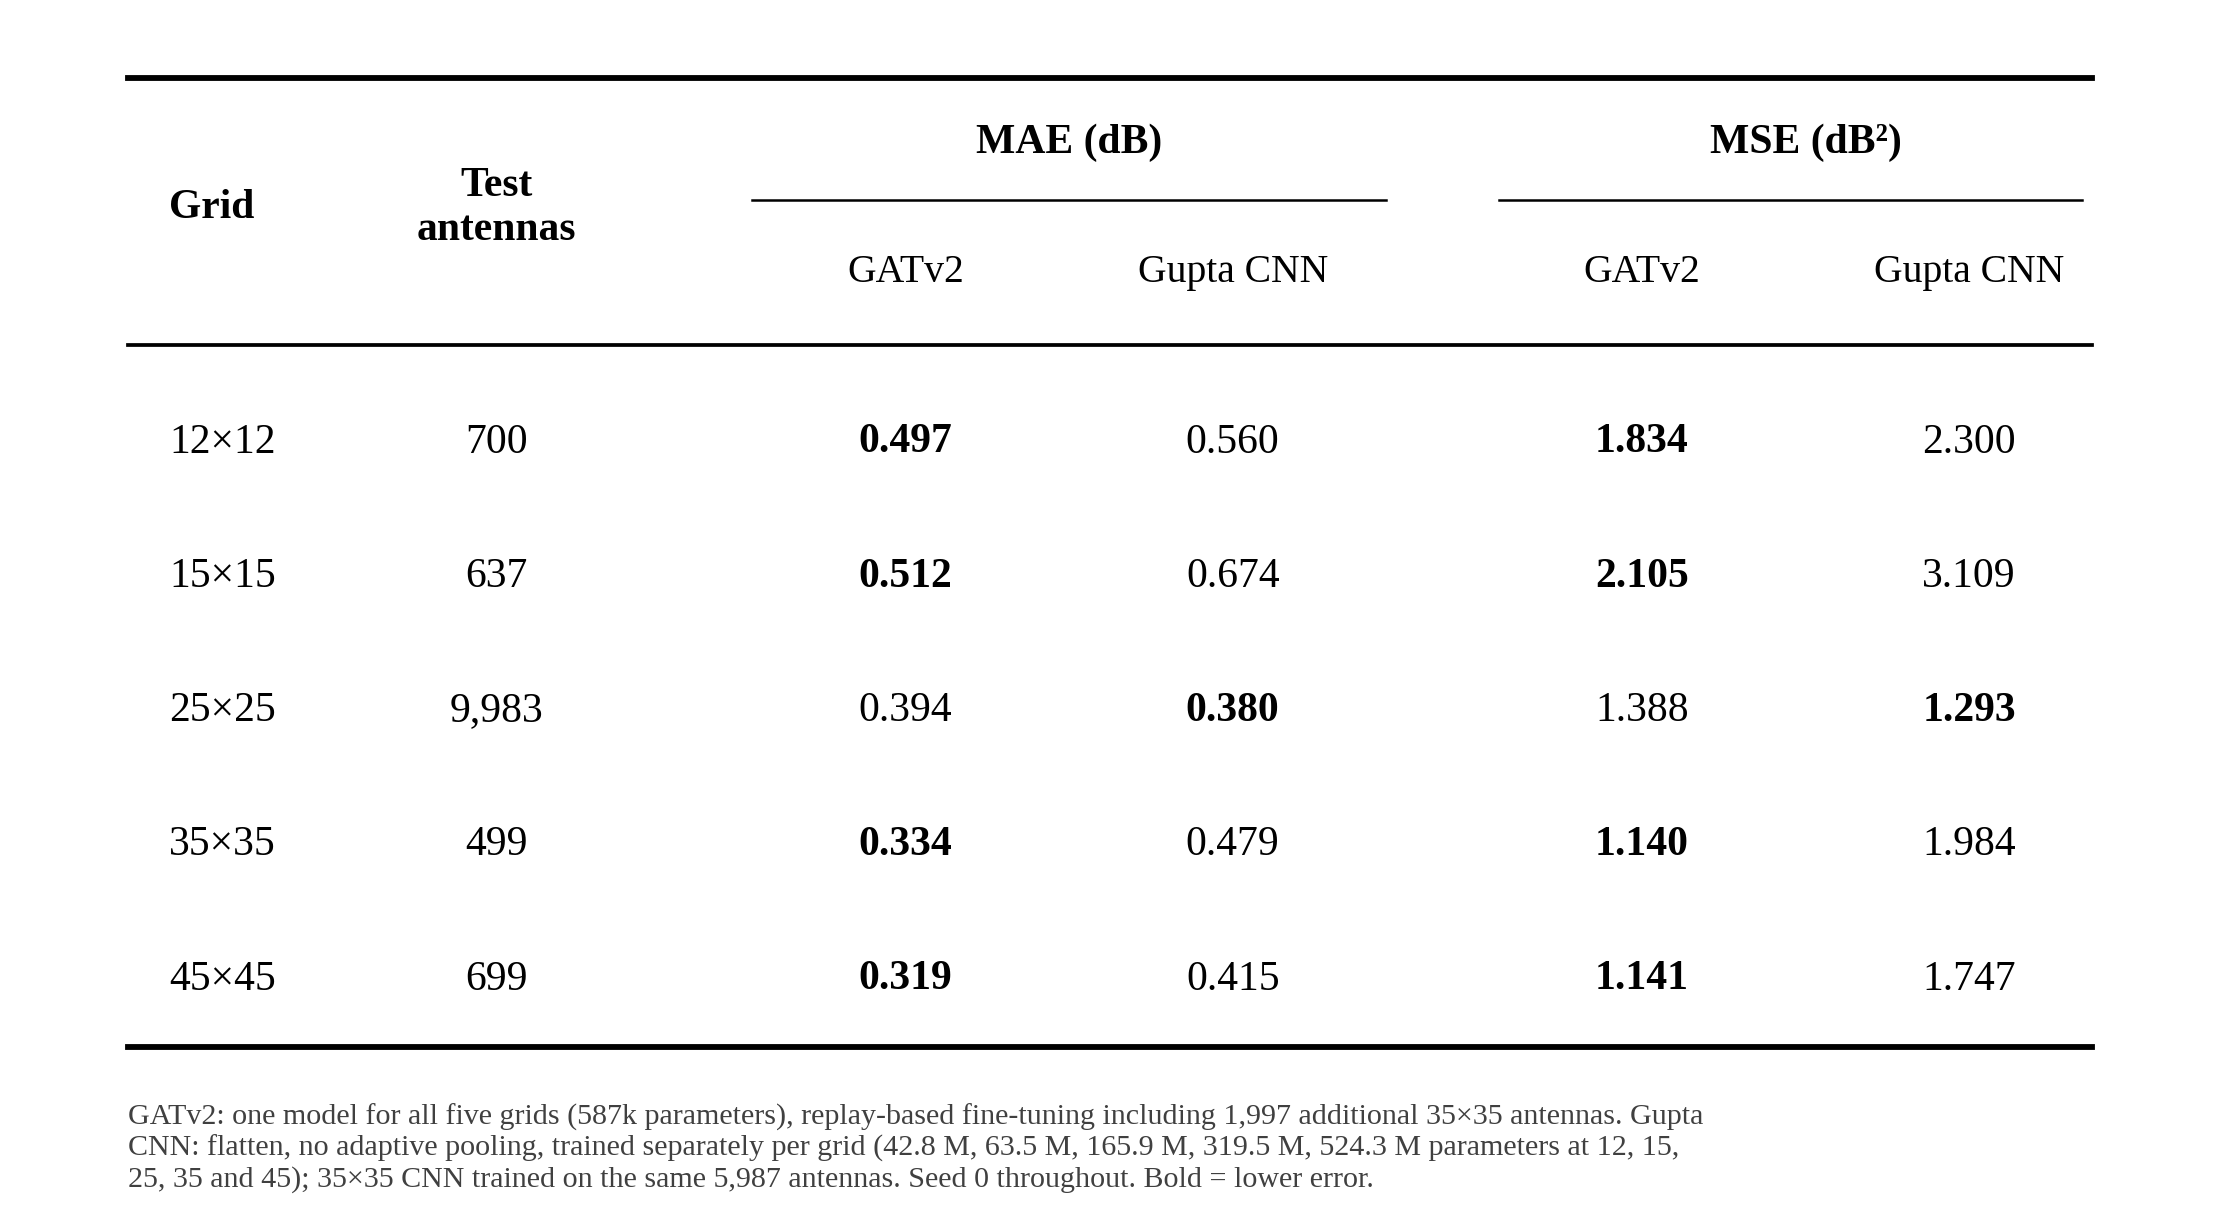

# Chunk 50 — 12×12 → 15×15 replay chain re-run from the Chunk 45 model

Final model: `ft15_from4_replay_from45_s0` (chain: replay35_new100_s0 → ft12_replay_from45 → ft15_from4_replay_from45). One test touch; 95% stratified bootstrap intervals. Every earlier test number reproduced to within 0.005.

| grid | model | MSE (dB²) | MAE (dB) | R² | AUROC |
|---|---|---|---|---|---|
| 12×12 | ft12_replay_from45_s0 | 1.852 [1.720, 1.999] | 0.498 [0.482, 0.515] | 0.654 [0.628, 0.678] | 0.789 |
| 12×12 | ft15_from4_replay_from45_s0 | 1.834 [1.705, 1.984] | 0.497 [0.482, 0.514] | 0.658 [0.632, 0.682] | 0.797 |
| 12×12 | ft15_from4_replay_p100_s0 | 1.812 [1.681, 1.960] | 0.489 [0.473, 0.506] | 0.662 [0.636, 0.686] | 0.799 |
| 15×15 | ft12_replay_from45_s0 | 2.251 [2.079, 2.435] | 0.530 [0.510, 0.551] | 0.672 [0.642, 0.699] | 0.828 |
| 15×15 | ft15_from4_replay_from45_s0 | 2.105 [1.934, 2.290] | 0.512 [0.492, 0.533] | 0.693 [0.662, 0.720] | 0.828 |
| 15×15 | ft15_from4_replay_p100_s0 | 2.106 [1.934,

In [11]:
# ── Table image and report ──
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
from matplotlib import font_manager
for f in glob.glob('/usr/share/fonts/truetype/liberation/*.ttf'):
    font_manager.fontManager.addfont(f)
FONT = next((f for f in ('Times New Roman', 'Liberation Serif', 'DejaVu Serif') if any(f == x.name for x in font_manager.fontManager.ttflist)), 'serif')
plt.rcParams.update({'font.family': 'serif', 'font.serif': [FONT], 'mathtext.fontset': 'stix', 'pdf.fonttype': 42})
CNN_P = {N: 6_163_473 - 257_000 + 256_000 * N * N + 1000 for N in GRIDS}
fig = plt.figure(figsize=(7.2, 3.55), dpi=300); ax = fig.add_axes([0, 0, 1, 1]); ax.axis('off')
X = [0.04, 0.20, 0.40, 0.56, 0.76, 0.92]; top = 0.93
ax.text(X[0], top - .06, 'Grid', ha='left', va='center', fontsize=10, fontweight='bold')
ax.text(X[1], top - .06, 'Test\nantennas', ha='center', va='center', fontsize=10, fontweight='bold')
ax.text((X[2] + X[3]) / 2, top - .02, 'MAE (dB)', ha='center', va='center', fontsize=10, fontweight='bold')
ax.text((X[4] + X[5]) / 2, top - .02, 'MSE (dB²)', ha='center', va='center', fontsize=10, fontweight='bold')
for x, l in zip(X[2:], ['GATv2', 'Gupta CNN', 'GATv2', 'Gupta CNN']):
    ax.text(x, top - .10, l, ha='center', va='center', fontsize=9.5)
ax.plot([.02, .98], [top + .02] * 2, lw=1.4, color='k')
ax.plot([X[2] - .075, X[3] + .075], [top - .055] * 2, lw=.6, color='k'); ax.plot([X[4] - .07, .975], [top - .055] * 2, lw=.6, color='k')
ax.plot([.02, .98], [top - .145] * 2, lw=.9, color='k')
y, dy = top - .205, .083
TAB = []
for N in GRIDS:
    gm, gs = get(FINAL, N, 'mae_db').estimate, get(FINAL, N, 'mse_db2').estimate
    cm, cs = cnn_value(N, 'mae_db'), cnn_value(N, 'mse_db2'); TAB.append(dict(grid=N, gatv2_mae=gm, cnn_mae=cm, gatv2_mse=gs, cnn_mse=cs))
    ax.text(X[0], y, f'{N}×{N}', ha='left', va='center', fontsize=10)
    ax.text(X[1], y, f'{len(S[N]["test"]):,}', ha='center', va='center', fontsize=10)
    for xg, xc, a, b in ((X[2], X[3], gm, cm), (X[4], X[5], gs, cs)):
        ax.text(xg, y, f'{a:.3f}', ha='center', va='center', fontsize=10, fontweight='bold' if a < b else 'normal')
        ax.text(xc, y, f'{b:.3f}', ha='center', va='center', fontsize=10, fontweight='bold' if b < a else 'normal')
    y -= dy
ax.plot([.02, .98], [y + dy / 2] * 2, lw=1.4, color='k')
note = ('GATv2: one model for all five grids (587k parameters), replay-based fine-tuning including 1,997 additional 35×35 antennas. '
        'Gupta CNN: flatten, no adaptive pooling, trained separately per grid (' + ', '.join(f'{CNN_P[N] / 1e6:.1f} M' for N in GRIDS)
        + ' parameters at 12, 15, 25, 35 and 45); 35×35 CNN trained on the same 5,987 antennas. Seed 0 throughout. Bold = lower error.')
ax.text(.02, y + dy / 2 - .035, '\n'.join(textwrap.wrap(note, 128)), ha='left', va='top', fontsize=7.2, color='0.25')
for ext in ('png', 'pdf'):
    fig.savefig(OUT(f'ch50_table_gatv2_vs_gupta_cnn.{ext}'), dpi=600 if ext == 'png' else None, bbox_inches='tight', pad_inches=.05, facecolor='white')
plt.show(); plt.close(fig)
pd.DataFrame(TAB).to_csv(OUT('ch50_table_values.csv'), index=False)

def fmt(mid, N, k):
    v = get(mid, N, k); return f'{v.estimate:.3f}' if np.isnan(v.lo) else f'{v.estimate:.3f} [{v.lo:.3f}, {v.hi:.3f}]'
L = ['# Chunk 50 — 12×12 → 15×15 replay chain re-run from the Chunk 45 model', '',
     f'Final model: `{FINAL}` (chain: {START_ID} → ft12_replay_from45 → ft15_from4_replay_from45). One test touch; '
     '95% stratified bootstrap intervals. Every earlier test number reproduced to within 0.005.', '',
     '| grid | model | MSE (dB²) | MAE (dB) | R² | AUROC |', '|---|---|---|---|---|---|']
for N in GRIDS:
    for mid in sorted({k[0] for k in PRED if k[1] == N}):
        L.append(f'| {N}×{N} | {mid} | {fmt(mid, N, "mse_db2")} | {fmt(mid, N, "mae_db")} | {fmt(mid, N, "r2")} | {fmt(mid, N, "auroc")} |')
L += ['', '## Paired comparisons (A − B, same test antennas)', PAIR.round(4).to_markdown(index=False), '',
      '## Pre-registered statements'] + [f'- **{k}:** {v}' for k, v in ANS.items()]
L += ['', '## Table values (new GATv2 vs Gupta CNN)', pd.DataFrame(TAB).round(4).to_markdown(index=False),
      '', '_25×25 Gupta CNN: Chunk 36 recorded values (checkpoint and per-sample file deleted); no paired test at 25×25._',
      '', '## Runs', RUNS_DF.drop(columns=['checkpoint_sha256'], errors='ignore').round(4).to_markdown(index=False)]
open(OUT('ch50_report.md'), 'w').write('\n'.join(L) + '\n'); print('\n'.join(L))

## 12. Guards
**What it checks:**
- one test touch
- every Chunk 50 checkpoint matches its recorded SHA-256
- stage 2 started from stage 1, and stage 1 from the Chunk 45 model
- no run was stopped by its epoch cap
- input files unchanged, and no earlier file modified
- every output named `ch50_*`

In [12]:
# ── Guards ──
fails = []
def guard(ok, msg):
    print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")
    if not ok: fails.append(msg)
R2 = pd.read_csv(RUNS)
guard(TEST_TOUCHES == 1, 'TEST touched exactly once')
guard(all(sha(p) == h for p, h in zip(R2.checkpoint, R2.checkpoint_sha256)), 'every ch50 checkpoint matches its recorded SHA-256')
chain_ok = all((r.init == Path(START_PATH).name) if r.arm == 'ft12_replay_from45' else (r.init == f'ch50_ft12_replay_from45_s{r.seed}.pt')
               for r in R2.itertuples())
guard(chain_ok, 'chain: Chunk 45 model -> stage 1 -> stage 2')
guard(not R2.budget_limited.any(), 'no run stopped by its epoch cap' if not R2.budget_limited.any() else
      f'BUDGET-LIMITED runs: {list(R2[R2.budget_limited].run_id)} (the best epoch was within 10 of the 60-epoch cap)')
guard(all(sha(p) == h for p, h in READ_SHA.items() if not Path(p).name.startswith('ch50_')), f'input files unchanged ({len(READ_SHA)})')
guard(all(os.path.getmtime(p) == t for p, t in PRIOR.items() if os.path.exists(p)), f'no earlier file modified ({len(PRIOR)})')
guard(all(Path(p).name.startswith('ch50_') for p in glob.glob(f'{ART}/ch50_*') + glob.glob(f'{CKPT}/ch50_*')), 'all outputs ch50_*')
assert not fails, fails
print('ALL GUARDS PASSED')

  [PASS] TEST touched exactly once
  [PASS] every ch50 checkpoint matches its recorded SHA-256
  [PASS] chain: Chunk 45 model -> stage 1 -> stage 2
  [PASS] no run stopped by its epoch cap
  [PASS] input files unchanged (29)
  [PASS] no earlier file modified (271)
  [PASS] all outputs ch50_*
ALL GUARDS PASSED
